In [35]:
import pandas as pd 
import numpy as np
import datetime         #Shows in my time zone COL.

AVZ-864 AIR2
8B5141QE

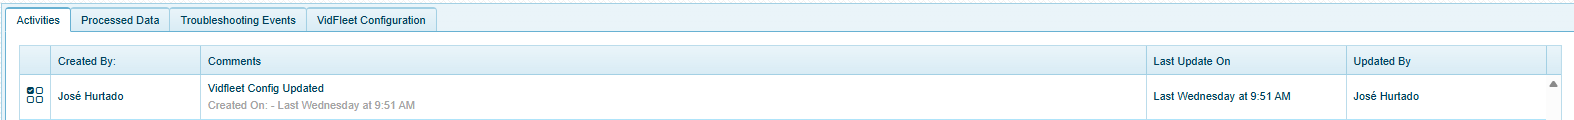
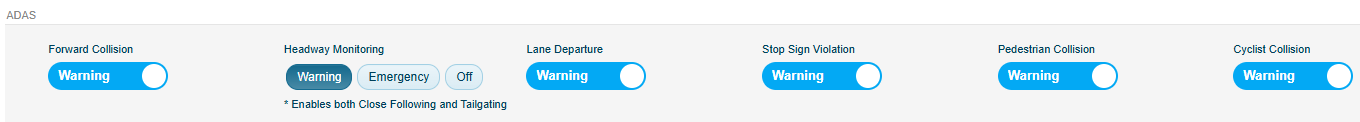

In [36]:
vf=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B5141QE.xlsx')
vf.info()

<class 'pandas.DataFrame'>
RangeIndex: 29015 entries, 0 to 29014
Columns: 332 entries, Message to Unnamed: 331
dtypes: float64(21), object(20), str(291)
memory usage: 73.5+ MB


In [37]:
vf['Message'].value_counts()

Message
{"notificationType":"TripInfo"              20332
{"notificationType":"CameraRunningInfo"      4083
{"notificationType":"AutoSnapshot"           2811
{"notificationType":"IgnitionStatus"         1005
{"notificationType":"CameraEvent"             440
{"notificationType":"MaintenanceWarning"      321
{"notificationType":"ParkingHeartbeat"         21
{"notificationType":"PowerEvent"                2
Name: count, dtype: int64

In [38]:
vf_camera_events=vf[vf['Message'].str.contains('CameraEvent')]
vf_camera_events['Unnamed: 4'].value_counts()

Unnamed: 4
event:"NO_SEATBELT"                  297
event:"USING_PHONE"                  103
event:"STOP_SIGN_VIOLATION"           19
event:"YAWN"                          10
event:"POTENTIAL_INCIDENT_LOW"         6
event:"HARD_BRAKE"                     4
event:"POTENTIAL_INCIDENT_MEDIUM"      1
Name: count, dtype: int64

In [39]:
vf_camera_events['Unnamed: 5'].value_counts()

Unnamed: 5
eventCategory:"DMS"                    410
eventCategory:"STOP_SIGN_VIOLATION"     19
eventCategory:"POTENTIAL_INCIDENT"       7
eventCategory:"HARD_BRAKE"               4
Name: count, dtype: int64

In [40]:
vf_autosnapshot=vf[vf['Unnamed: 5'].str.contains('http')]
vf_autosnapshot['Unnamed: 5']#.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sedisa\snapshot.csv')

1        url:"https://cdn.vidfleet-api.gpstrackit.com/c...
15       url:"https://cdn.vidfleet-api.gpstrackit.com/c...
31       url:"https://cdn.vidfleet-api.gpstrackit.com/c...
47       url:"https://cdn.vidfleet-api.gpstrackit.com/c...
60       url:"https://cdn.vidfleet-api.gpstrackit.com/c...
                               ...                        
28979    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
28999    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
29002    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
29010    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
29013    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
Name: Unnamed: 5, Length: 2811, dtype: str

In [41]:
vf_date_time=vf[vf['Unnamed: 3'].str.contains('time')]
vf_date_time['Unnamed: 3']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
print(vf_date_time.iloc[0,103])

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,3][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i])

nan
2026-09-30 19:28:37.066000  ->  1790814517.066
2026-09-30 19:38:37.600000  ->  1790815117.6
2026-09-30 19:58:38.132000  ->  1790816318.132
2026-09-30 20:18:37  ->  1790817517.0
2026-09-30 20:28:37  ->  1790818117.0
2026-09-30 20:32:41  ->  1790818361.0
2026-09-30 23:49:51  ->  1790830191.0
2026-09-30 23:52:31  ->  1790830351.0
2026-10-01 05:44:24  ->  1790851464.0
2026-10-01 05:54:24.066000  ->  1790852064.066
2026-10-01 06:04:24.133000  ->  1790852664.133
2026-10-01 06:14:24.133000  ->  1790853264.133
2026-10-01 06:34:23.400000  ->  1790854463.4
2026-10-01 07:38:10  ->  1790858290.0
2026-10-01 08:08:08.333000  ->  1790860088.333
2026-10-01 08:13:14.600000  ->  1790860394.6
2026-10-01 08:34:59  ->  1790861699.0
2026-10-01 08:42:45  ->  1790862165.0
2026-10-01 12:59:44  ->  1790877584.0
2026-10-01 13:09:43.066000  ->  1790878183.066
2026-10-01 13:19:41.266000  ->  1790878781.266
2026-10-01 13:29:41.266000  ->  1790879381.266
2026-10-01 13:39:41.400000  ->  1790879981.4
2026-10-01 13

In [42]:
vf_autosnapshot=vf[vf['Unnamed: 5'].str.contains('http')]
vf_autosnapshot_date=[]
aux_date_time_as=[]
epoch_date_as=[]
vf_autosnapshot['Date']='NaN'

for i in range(0,vf_autosnapshot.shape[0]):
    aux_date_time_as.append(float(vf_date_time.iloc[i,3][5:18])/1000)
    epoch_date_as.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_autosnapshot.iloc[i,104]=str(epoch_date_as[i])

#vf_autosnapshot[['Unnamed: 5','Unnamed: 3','Date']].to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sedisa\autosnap_vck379.csv')       #Edit.

NO_SEATBELT


In [43]:
vf_no_seatbelt=vf[vf['Unnamed: 4'].str.contains('NO_SEATBELT')]
#vf_no_seatbelt

vf_date_time=vf_no_seatbelt[vf_no_seatbelt['Unnamed: 9'].str.contains('time')]
#vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))    
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-05 18:32:55  ->  1791243175.0  ->  speed:67.51651
2026-10-05 18:35:24  ->  1791243324.0  ->  speed:61.38454
2026-10-06 13:07:28  ->  1791310048.0  ->  speed:16.145737
2026-10-06 15:23:05  ->  1791318185.0  ->  speed:15.521612
2026-10-07 10:15:20  ->  1791386120.0  ->  speed:29.350496
2026-10-07 10:28:36  ->  1791386916.0  ->  speed:16.619848
2026-10-07 10:37:20  ->  1791387440.0  ->  speed:17.327312
2026-10-07 13:08:32  ->  1791396512.0  ->  speed:16.138329
2026-10-07 15:18:32  ->  1791404312.0  ->  speed:18.114412
2026-10-07 16:44:37  ->  1791409477.0  ->  speed:16.451317
2026-10-08 06:05:52  ->  1791457552.0  ->  speed:18.912624
2026-10-08 06:50:09  ->  1791460209.0  ->  speed:19.070044
2026-10-08 07:02:36  ->  1791460956.0  ->  speed:18.331097
2026-10-08 07:13:01  ->  1791461581.0  ->  speed:14.873412
2026-10-08 07:22:22  ->  1791462142.0  ->  speed:19.244131
2026-10-08 07:32:52  ->  1791462772.0  ->  speed:25.4187
2026-10-08 07:42:09  ->  1791463329.0  ->  speed:14.441896
2

USING_PHONE

In [44]:
using_phone=vf[vf['Unnamed: 4'].str.contains('USING_PHONE')]
#vf_no_seatbelt

vf_date_time=using_phone[using_phone['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-01 07:49:49  ->  1790858989.0  ->  speed:62.064224
2026-10-01 16:24:58  ->  1790889898.0  ->  speed:63.62546
2026-10-06 18:20:34  ->  1791328834.0  ->  speed:12.925107
2026-10-06 19:29:28  ->  1791332968.0  ->  speed:14.784516
2026-10-07 05:40:08  ->  1791369608.0  ->  speed:28.694887
2026-10-07 06:03:15  ->  1791370995.0  ->  speed:11.536108
2026-10-07 06:35:40  ->  1791372940.0  ->  speed:17.21434
2026-10-07 06:37:52  ->  1791373072.0  ->  speed:9.956352
2026-10-07 08:20:44  ->  1791379244.0  ->  speed:20.636835
2026-10-07 13:48:55  ->  1791398935.0  ->  speed:9.595211
2026-10-07 13:54:22  ->  1791399262.0  ->  speed:16.92728
2026-10-07 16:46:30  ->  1791409590.0  ->  speed:24.146376
2026-10-07 17:53:47  ->  1791413627.0  ->  speed:28.685629
2026-10-08 08:22:17  ->  1791465737.0  ->  speed:0.924148
2026-10-08 11:25:41  ->  1791476741.0  ->  speed:8.96368
2026-10-08 16:03:47  ->  1791493427.0  ->  speed:1.36122
2026-10-08 16:37:33  ->  1791495453.0  ->  speed:22.01102
2026-10-

DROWSINESS

In [45]:
drowsiness=vf[vf['Unnamed: 4'].str.contains('DROWSINESS')]
#vf_no_seatbelt

vf_date_time=drowsiness[drowsiness['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

YAWN

In [46]:
yawn=vf[vf['Unnamed: 4'].str.contains('YAWN')]
#vf_no_seatbelt

vf_date_time=yawn[yawn['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-01 08:02:42  ->  1790859762.0  ->  speed:79.34709
2026-10-02 09:33:32  ->  1790951612.0  ->  speed:72.102066
2026-10-21 05:43:44  ->  1792579424.0  ->  speed:53.759857
2026-10-21 08:02:32  ->  1792587752.0  ->  speed:82.55105
2026-10-21 14:46:22  ->  1792611982.0  ->  speed:72.183556
2026-10-22 08:42:40  ->  1792676560.0  ->  speed:87.514404
2026-10-22 07:04:32  ->  1792670672.0  ->  speed:85.091995
2026-10-21 14:55:19  ->  1792612519.0  ->  speed:75.5579
2026-10-27 09:31:18  ->  1793111478.0  ->  speed:70.20562
2026-10-27 09:48:10  ->  1793112490.0  ->  speed:74.08741


SHARP_TURN

In [47]:
sharp_turn=vf[vf['Unnamed: 4'].str.contains('SHARP')]
#vf_no_seatbelt

vf_date_time=sharp_turn[sharp_turn['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

HARD_BRAKE

In [48]:
hard_brake=vf[vf['Unnamed: 4'].str.contains('HARD')]
#vf_no_seatbelt

vf_date_time=hard_brake[hard_brake['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-03 20:20:24  ->  1791076824.0  ->  speed:11.795388
2026-10-13 05:41:05  ->  1791888065.0  ->  speed:11.799092
2026-10-24 05:44:57  ->  1792838697.0  ->  speed:12.119487
2026-10-28 07:29:31  ->  1793190571.0  ->  speed:14.608575


STOP_SIGN_VIOLATION

In [49]:
ssv=vf[vf['Unnamed: 4'].str.contains('STOP_SIGN_VIOLATION')]
#vf_no_seatbelt

vf_date_time=ssv[ssv['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]
event=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])
    event.append(vf_date_time.iloc[i,4])

ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B5141QE_ssv.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i],' -> ',event[i])

2026-10-06 20:21:48  ->  1791336108.0  ->  speed:22.583288  ->  event:"STOP_SIGN_VIOLATION"
2026-10-07 17:53:28.475000  ->  1791413608.475  ->  speed:19.801584  ->  event:"STOP_SIGN_VIOLATION"
2026-10-07 20:26:41.541000  ->  1791422801.541  ->  speed:20.533125  ->  event:"STOP_SIGN_VIOLATION"
2026-10-09 05:54:40.686000  ->  1791543280.686  ->  speed:25.850216  ->  event:"STOP_SIGN_VIOLATION"
2026-10-12 20:27:40.285000  ->  1791854860.285  ->  speed:17.351389  ->  event:"STOP_SIGN_VIOLATION"
2026-10-13 06:12:46.820000  ->  1791889966.82  ->  speed:32.20628  ->  event:"STOP_SIGN_VIOLATION"
2026-10-16 06:12:02  ->  1792149122.0  ->  speed:30.411692  ->  event:"STOP_SIGN_VIOLATION"
2026-10-20 06:05:25  ->  1792494325.0  ->  speed:27.830004  ->  event:"STOP_SIGN_VIOLATION"
2026-10-20 17:51:51  ->  1792536711.0  ->  speed:24.596413  ->  event:"STOP_SIGN_VIOLATION"
2026-10-20 20:26:47.441000  ->  1792546007.441  ->  speed:21.172064  ->  event:"STOP_SIGN_VIOLATION"
2026-10-22 09:00:44  ->  179

POTENTIAL_INCIDENT

In [50]:
pi=vf[vf['Unnamed: 4'].str.contains('POTENTIAL_INCIDENT')]
#vf_no_seatbelt

vf_date_time=pi[pi['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]
event=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])
    event.append(vf_date_time.iloc[i,4])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ','->',event[i],'->',speed[i])

2026-10-08 07:55:23  ->  1791464123.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:15.912384
2026-10-10 08:55:25  ->  1791640525.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:15.967944
2026-10-13 05:41:05  ->  1791888065.0  ->  -> event:"POTENTIAL_INCIDENT_MEDIUM" -> speed:11.799092
2026-10-15 13:18:40  ->  1792088320.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:5.735643
2026-10-16 09:55:27  ->  1792162527.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:19.77936
2026-10-17 08:45:10  ->  1792244710.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:13.221427
2026-10-17 08:53:37  ->  1792245217.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:16.962467
